# 04 · Dónde se equivoca el modelo y qué significa para comprar vivienda

Qué hace. Analiza los errores del modelo final fuera de muestra: sesgo por quintil de la predicción, compresión de los
precios altos, avisos con variables fuera del rango del entrenamiento, cuántas veces predice más de 10 % por encima o
por debajo, qué variables mueven la predicción (valores SHAP) y, con esos errores, simula una política de compras con
ofertas automáticas para medir cuánta precisión haría falta para que fuera rentable.

Cómo. Usa dos conjuntos de predicciones fuera de muestra del LightGBM con Catastro, guardados en `stores/`:
Chapinero fuera (307 avisos; el modelo no vio Chapinero) y kNNDM (38.644 avisos de toda Bogotá, con la distancia al vecino
de entrenamiento parecida a la de la prueba). Se aplica el mismo ×1,08 del envío final. Los valores SHAP se leen de los
datos de las presentaciones (`document/presentaciones/datos/`, solo lectura). Con `RECALCULAR = True` se vuelve a ajustar
el LightGBM de una semilla y se recalculan los SHAP en `stores/recalculo/`.

Para qué. Responde la Etapa 4 del enunciado: dónde falla el modelo, si sobrestima o subestima de forma sistemática y si
se puede confiar en él para comprar, con el antecedente de Zillow Offers (pérdidas de cerca de 500 millones de dólares).

Conceptos de clase que usa:

| Concepto | Dónde se enseña | Sección |
|---|---|---|
| Los árboles no extrapolan: fuera del rango usan la última hoja | Lecture 14, cuaderno 01_SpatialData | 3 |
| Valores de Shapley y SHAP; TreeSHAP; lo que $\phi_j$ no es | Lecture 13, diap. 66 a 80 | 5 |
| Pérdida asimétrica: sobrestimar destruye capital | Enunciado, sección 1 (caso Zillow) | 6 |
| Maldición del ganador (selección adversa en ofertas aceptadas) | Enunciado, sección 1; artículo "Flip Flop" de Stanford GSB citado en el enunciado | 6 |

Orden de ejecución: después de `02` y `03`. Tiempo: cerca de 1 minuto con `RECALCULAR = False`.

## 0. Configuración y predicciones fuera de muestra

In [1]:
# False: lee resultados guardados. True: reajusta el LightGBM de una semilla para los SHAP y escribe en stores/recalculo/.
RECALCULAR = False

import warnings
warnings.filterwarnings("ignore")
import json
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import cuadernos_utils as cu
from cuadernos_utils import coma, tabla_coma

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
t0 = time.time()


def guardar_figura(fig, nombre):
    fig.savefig(cu.VIEWS / f"04_{nombre}.png")


def ajuste(p):
    # Ajuste final del envío 02: 654 + 1,08 (ŷ − 654)
    return cu.CENTRO + cu.FACTOR * (p - cu.CENTRO)


F = cu.cargar_flujo("aleatoria")
g, y, idx_tr, idx_te = F.g, F.y, F.idx_tr, F.idx_te

rk = pd.read_parquet(cu.STORES / "rk_knndm_oof_lightgbm_con.parquet")
oof_l = pd.read_parquet(cu.STORES / "cv_clase_oof_lightgbm_con.parquet")
ch = oof_l[oof_l["esquema"].str.startswith("Chapinero")]
ESQ = {"kNNDM": pd.DataFrame({"idx": rk["idx"].values, "real": rk["real"].values, "pred": rk["base"].values}),
       "Chapinero fuera": ch[["idx", "real", "pred"]].reset_index(drop=True)}
for o in ESQ.values():
    o["pf"] = ajuste(o["pred"])
for k, o in ESQ.items():
    print(f"{k}: {coma(len(o), 0)} avisos | MAE sin ajuste {coma(np.abs(o['pred'] - o['real']).mean())} | "
          f"con ×1,08 {coma(np.abs(o['pf'] - o['real']).mean())} | sesgo con ×1,08 {coma((o['pf'] - o['real']).mean())}")

[  0.1 min] Variables: estructurales 15, externas 24 + adicionales 26, texto 83, BETO PCA 32, BETO ajustado 1


[  0.1 min] AUC adversarial (composición): 0.922


[  0.1 min] V3: 20,144 avisos en 80 bloques de 1 km


[  0.2 min] Variables: sin Catastro 150 | con Catastro 161 (+ puntaje de texto)


[  0.2 min] aleatoria: 5 pliegues | validación 38,644 | entrenamiento medio 30,915 | parada interna media 6,183


[  0.2 min] Chapinero (imitando el taller): 1 pliegues | validación 307 | entrenamiento medio 38,337 | parada interna media 2,074


[  0.2 min] Fin


kNNDM: 38.644 avisos | MAE sin ajuste 111,7 | con ×1,08 112,2 | sesgo con ×1,08 -0,2
Chapinero fuera: 307 avisos | MAE sin ajuste 143,8 | con ×1,08 140,8 | sesgo con ×1,08 -41,1


## 1. Sesgo por cuantil de la predicción

La empresa ve la predicción, no el precio. Por eso el sesgo se mide agrupando por cuantil de la predicción $q(\hat y)$:

$$\text{sesgo}_q = \frac{1}{n_q}\sum_{i : q(\hat y_i) = q} (\hat y_i - y_i)$$

Agrupar por el precio real induce regresión a la media: los avisos más caros saldrían siempre subestimados, aunque el
modelo estuviera calibrado.

Diferencia máxima con ppt_calibracion2.csv: 0,000000


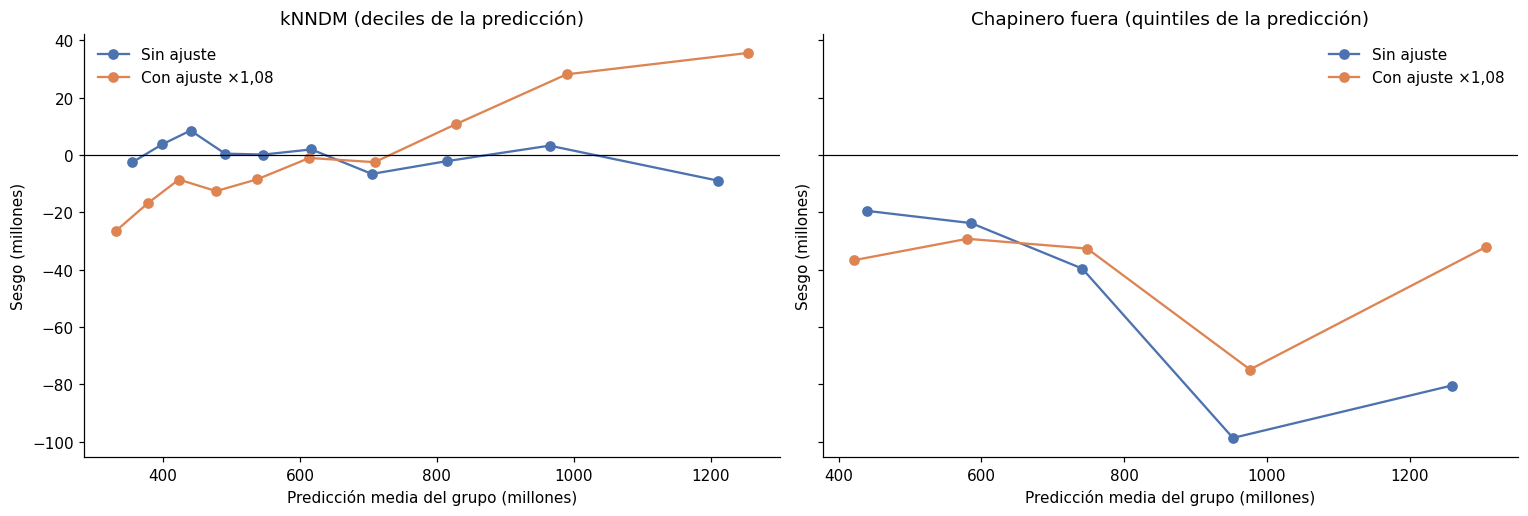

versión                 Con ajuste ×1,08 Sin ajuste
esquema         cuantil                            
Chapinero fuera 1                  -36,7      -19,5
                2                  -29,2      -23,8
                3                  -32,7      -39,6
                4                  -74,8      -98,7
                5                  -32,0      -80,4
kNNDM           1                  -26,4       -2,5
                2                  -16,8        3,6
                3                   -8,6        8,5
                4                  -12,6        0,4
                5                   -8,5        0,1
                6                   -1,1        1,9
                7                   -2,5       -6,6
                8                   10,7       -2,2
                9                   28,1        3,2
                10                  35,6       -8,9

In [2]:
filas = []
for nombre, o in ESQ.items():
    nq = 10 if nombre == "kNNDM" else 5
    for col, version in (("pred", "Sin ajuste"), ("pf", "Con ajuste ×1,08")):
        q = pd.qcut(o[col], nq, labels=False)
        t = o.groupby(q + 1).agg(pred_media=(col, "mean"), real_media=("real", "mean"), n=("real", "size")).reset_index(names="cuantil")
        t["sesgo"] = t["pred_media"] - t["real_media"]
        t["esquema"], t["versión"] = nombre, version
        filas.append(t)
cal = pd.concat(filas)
ref = pd.read_csv(cu.DATOS_PPT / "ppt_calibracion2.csv")
print("Diferencia máxima con ppt_calibracion2.csv:", coma(np.abs(cal["sesgo"].values - ref["sesgo"].values).max(), 6))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, nombre in zip(axes, ESQ):
    for version, col in (("Sin ajuste", "#4C72B0"), ("Con ajuste ×1,08", "#DD8452")):
        t = cal[(cal["esquema"] == nombre) & (cal["versión"] == version)]
        ax.plot(t["pred_media"], t["sesgo"], "o-", color=col, label=version)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"{nombre} ({'deciles' if nombre == 'kNNDM' else 'quintiles'} de la predicción)",
           xlabel="Predicción media del grupo (millones)", ylabel="Sesgo (millones)")
    ax.legend(frameon=False)
fig.tight_layout()
guardar_figura(fig, "sesgo_por_cuantil")
plt.show()
t = cal.pivot_table(index=["esquema", "cuantil"], columns="versión", values="sesgo")
tabla_coma(t)

Lectura. En Bogotá (kNNDM) el modelo sin ajuste está calibrado: el sesgo va de −9 a +9 millones en todos los deciles. En
Chapinero fuera subestima en todos los quintiles, de −19 a −99. El ×1,08 reduce esa subestimación (de −29 a −75) a costa
de sobrestimar las predicciones altas del resto de Bogotá (+28 y +36 en los dos deciles superiores). El ajuste es una
apuesta por Chapinero, no una mejora general.

## 2. Compresión de los precios altos

In [3]:
filas = []
for nombre, o in ESQ.items():
    for corte, et in ((-np.inf, "todos"), (1000, "precio real > 1.000")):
        m = o["real"] > corte
        filas.append({"esquema": nombre, "avisos": et, "n": int(m.sum()),
                      "sesgo sin ajuste": (o["pred"] - o["real"])[m].mean(), "sesgo con ×1,08": (o["pf"] - o["real"])[m].mean()})
t_ = pd.DataFrame(filas)
tabla_coma(t_).assign(n=t_["n"].map(lambda v: coma(v, 0))).set_index(["esquema", "avisos"])

n sesgo sin ajuste sesgo con ×1,08
esquema         avisos                                                      
kNNDM           todos                38.644             -0,2            -0,2
                precio real > 1.000   5.052           -209,5          -175,2
Chapinero fuera todos                   307            -52,3           -41,1
                precio real > 1.000      94           -205,0          -166,3

## 3. Avisos fuera del rango del entrenamiento

Un árbol no extrapola: a cualquier valor por encima del último corte le asigna la misma hoja (Lecture 14, cuaderno
01_SpatialData). Se cuenta, para cada aviso, cuántas de 7 variables quedan fuera del rango entre los percentiles 1 y 99
del entrenamiento. Para la prueba la referencia es todo el entrenamiento; para Chapinero fuera, el entrenamiento sin
Chapinero.

In [4]:
VARS = {"ln_dist_area_protegida_m": "Distancia a los cerros", "ln_n_embajada_1000m": "Embajadas a 1 km",
        "ln_n_hotel_1000m": "Hoteles a 1 km", "ln_n_oficina_1000m": "Oficinas a 1 km", "ln_vref_300m": "Valor del suelo a 300 m",
        "area_imp": "Área", "elevacion_m": "Elevación"}


def cuenta_fuera(idx_ref, idx_eval):
    n, por_var = np.zeros(len(idx_eval), int), {}
    for v, et in VARS.items():
        lo, hi = np.nanpercentile(g[v].values[idx_ref], [1, 99])
        val = g[v].values[idx_eval]
        marca = (val < lo) | (val > hi)
        por_var[et] = 100 * marca.mean()
        n += marca.astype(int)
    return n, por_var


n_te, pv = cuenta_fuera(idx_tr, idx_te)
print("Prueba, % fuera del rango p1 a p99 del entrenamiento por variable:")
print(pd.Series(pv).map(lambda v: coma(v)).to_string())
print(f"Avisos de prueba: {coma(100 * np.mean(n_te == 0))} % dentro en todas, {coma(100 * np.mean(n_te == 1))} % con una fuera, "
      f"{coma(100 * np.mean(n_te >= 2))} % con dos o más")

a_sin_chap = F.PLIEGUES["Chapinero"][0]
o = ESQ["Chapinero fuera"]
n_ch, _ = cuenta_fuera(a_sin_chap, o["idx"].to_numpy())
o["grupo de rango"] = np.where(n_ch >= 2, "Dos o más fuera", np.where(n_ch == 1, "Una fuera", "Dentro del rango"))
reg = o.groupby("grupo de rango").apply(lambda t: pd.Series({
    "n": str(len(t)), "MAE": np.mean(np.abs(t["pf"] - t["real"])), "error abs. mediano (%)": 100 * np.median(np.abs(t["pf"] / t["real"] - 1)),
    "sesgo": np.mean(t["pf"] - t["real"]), "% más de 10 % arriba": 100 * np.mean(t["pf"] / t["real"] - 1 > 0.1)}))
print("\nChapinero fuera (con ×1,08), según cuántas variables quedan fuera del rango del entrenamiento sin Chapinero:")
tabla_coma(reg)

Prueba, % fuera del rango p1 a p99 del entrenamiento por variable:
Distancia a los cerros     10,4
Embajadas a 1 km           29,7
Hoteles a 1 km              0,6
Oficinas a 1 km             0,9
Valor del suelo a 300 m    59,5
Área                        0,8
Elevación                  17,9
Avisos de prueba: 26,6 % dentro en todas, 33,1 % con una fuera, 40,3 % con dos o más

Chapinero fuera (con ×1,08), según cuántas variables quedan fuera del rango del entrenamiento sin Chapinero:


,n,MAE,error abs. mediano (%),sesgo,% más de 10 % arriba
grupo de rango,,,,,
Dentro del rango,45,"133,1","14,9","-53,9","28,9"
Dos o más fuera,152,"158,5","14,5","-55,2","23,0"
Una fuera,110,"119,6","11,6","-16,3","30,9"


Lectura. El valor del suelo a 300 m es la variable que más se sale (59,5 % de la prueba). Pero el error porcentual
mediano es parecido en los tres grupos de Chapinero fuera (15 %, 12 % y 15 %): estar fuera de rango sirve para priorizar
la revisión de un aviso, no para separar avisos confiables de no confiables.

## 4. ¿Predice un precio mayor o menor?

Para un comprador, predecir más de 10 % por encima del precio significa pagar de más; predecir más de 10 % por debajo
significa perder el negocio.

In [5]:
filas = []
for nombre, o in ESQ.items():
    for col, version in (("pred", "Sin ajuste"), ("pf", "Con ajuste ×1,08")):
        e = 100 * (o[col] / o["real"] - 1)
        filas.append({"esquema": nombre, "versión": version, "% más de 10 % arriba": (e > 10).mean() * 100,
                      "% dentro de ±10 %": (e.abs() <= 10).mean() * 100, "% más de 10 % abajo": (e < -10).mean() * 100,
                      "error abs. mediano (%)": e.abs().median(), "MAE": np.abs(o[col] - o["real"]).mean()})
lados = pd.DataFrame(filas).set_index(["esquema", "versión"])
o = ESQ["Chapinero fuera"]
e = 100 * (o["pf"] / o["real"] - 1)
lq = pd.DataFrame({"quintil": pd.qcut(o["pf"], 5, labels=False) + 1, "arriba": e > 10, "abajo": e < -10, "pf": o["pf"]}).groupby("quintil").agg(
    **{"predicción mínima": ("pf", "min"), "predicción máxima": ("pf", "max"), "% más de 10 % arriba": ("arriba", "mean"),
       "% más de 10 % abajo": ("abajo", "mean")})
lq[["% más de 10 % arriba", "% más de 10 % abajo"]] *= 100
display(tabla_coma(lados))
print("Chapinero fuera con ×1,08, por quintil de la predicción:")
tabla_coma(lq)

% más de 10 % arriba % dentro de ±10 %  \
esquema         versión                                                   
kNNDM           Sin ajuste                       35,8              40,1   
                Con ajuste ×1,08                 32,6              40,7   
Chapinero fuera Sin ajuste                       25,7              40,7   
                Con ajuste ×1,08                 26,7              40,1   

                                 % más de 10 % abajo error abs. mediano (%)  \
esquema         versión                                                       
kNNDM           Sin ajuste                      24,1                   13,0   
                Con ajuste ×1,08                26,7                   12,8   
Chapinero fuera Sin ajuste                      33,6                   14,3   
                Con ajuste ×1,08                33,2                   12,9   

                                    MAE  
esquema         versión                  
kNNDM           Sin ajuste        111,7  
                Con ajuste ×1,08  112,2  
Chapinero fuera Sin ajuste        143,8  
                Con ajuste ×1,08  140,8

Chapinero fuera con ×1,08, por quintil de la predicción:


,predicción mínima,predicción máxima,% más de 10 % arriba,% más de 10 % abajo
quintil,,,,
1,"344,7","506,4","31,7","39,7"
2,"507,0","641,0","26,2","31,1"
3,"641,7","845,1","26,7","28,3"
4,"846,2","1.112,0","32,8","41,0"
5,"1.133,2","1.575,3","16,1","25,8"


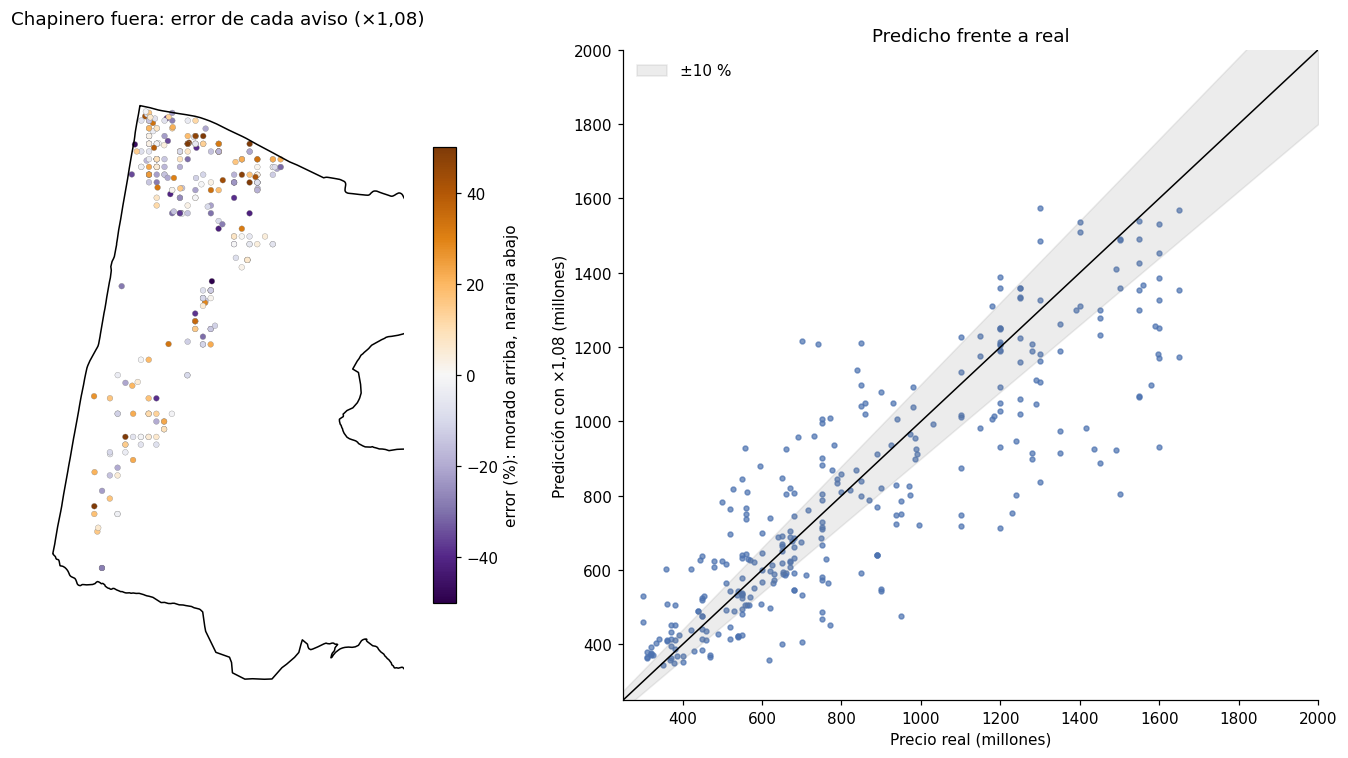

In [6]:
# Error porcentual de Chapinero fuera en la coordenada exacta de cada aviso
loc = gpd.read_file(cu.STORES / "localidades_bogota.geojson").to_crs("EPSG:9377")
chap = loc[loc["localidad"] == "Chapinero"]
o = ESQ["Chapinero fuera"].assign(x=F.xs[ESQ["Chapinero fuera"]["idx"]], yy=F.ys[ESQ["Chapinero fuera"]["idx"]])
o["error_pct"] = 100 * (o["pf"] / o["real"] - 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1, 1.2]})
sc = axes[0].scatter(o["x"], o["yy"], c=o["error_pct"].clip(-50, 50), cmap="PuOr_r", vmin=-50, vmax=50, s=14, edgecolor="grey", lw=0.2)
chap.boundary.plot(ax=axes[0], color="black", lw=1)
b_ = chap.total_bounds
axes[0].set_xlim(b_[0] - 300, b_[0] + 0.55 * (b_[2] - b_[0])); axes[0].set_ylim(b_[1] - 300, b_[3] + 800); axes[0].set_axis_off()
plt.colorbar(sc, ax=axes[0], shrink=0.7, label="error (%): morado arriba, naranja abajo")
axes[0].set_title("Chapinero fuera: error de cada aviso (×1,08)")
axes[1].scatter(o["real"], o["pf"], s=10, color="#4C72B0", alpha=0.7)
lim = [250, 2000]
axes[1].plot(lim, lim, color="black", lw=1)
axes[1].fill_between(lim, [0.9 * v for v in lim], [1.1 * v for v in lim], color="grey", alpha=0.15, label="±10 %")
axes[1].set(xlim=lim, ylim=lim, xlabel="Precio real (millones)", ylabel="Predicción con ×1,08 (millones)",
            title="Predicho frente a real")
axes[1].legend(frameon=False)
fig.tight_layout()
guardar_figura(fig, "errores_chapinero")
plt.show()

Lectura. En Chapinero fuera, con el ×1,08, el 26,7 % de las predicciones queda más de 10 % arriba (pagar de más) y el
33,2 % más de 10 % abajo (perder el negocio). Por quintil, el riesgo de pagar de más va de 16 % a 33 %: no se concentra en
un segmento que se pueda excluir.

## 5. Qué mueve la predicción: valores SHAP

Para un aviso $\mathbf{x}$, el valor de Shapley de la variable $j$ reparte la diferencia entre su predicción y la
predicción media promediando sobre todos los órdenes en que pueden entrar las variables (Lecture 13, diap. 72 a 74):

$$\phi_j = \sum_{S \subseteq N \setminus \{j\}} \frac{|S|!\,(p - |S| - 1)!}{p!}\big[v(S \cup \{j\}) - v(S)\big], \qquad
\hat f(\mathbf{x}) = \phi_0 + \sum_{j=1}^{p} \phi_j, \quad \phi_0 = \mathbb{E}[\hat f(X)]$$

Para árboles se calculan exactos con TreeSHAP (`pred_contrib=True` de LightGBM). Se usa el LightGBM final con una semilla
(2026, 252 árboles). Advertencias de la clase: $\phi_j$ no es un efecto causal ni el cambio al sacar la variable y
reentrenar; es un reparto contable de la predicción, y con variables correlacionadas se reparte entre ellas.

In [7]:
NOMBRES = F.COLUMNAS["con"] + ["puntaje_texto_ridge"]
if RECALCULAR:
    import lightgbm as lgb
    X = np.c_[g[F.COLUMNAS["con"]].to_numpy(float), cu.puntaje_guardado(F, "final")]
    Xtr, ytr = X[idx_tr], y[idx_tr]
    i_in, i_iv = F.mu.bloques_internos(F.xs[idx_tr], F.ys[idx_tr], semilla=F.SEMILLA)
    p = dict(objective="l2", learning_rate=0.05, num_leaves=63, min_child_samples=20, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.7, reg_lambda=1.0, n_estimators=5000, random_state=F.SEMILLA, verbose=-1, n_jobs=4)
    m = lgb.LGBMRegressor(**p).fit(Xtr[i_in], ytr[i_in], eval_set=[(Xtr[i_iv], ytr[i_iv])], eval_metric="l2",
                                   callbacks=[lgb.early_stopping(100, verbose=False)])
    p["n_estimators"] = max(int(m.best_iteration_ or 100), 50)
    contrib = lgb.LGBMRegressor(**p).fit(Xtr, ytr).predict(X[idx_te], pred_contrib=True)
    shap_te = pd.DataFrame(contrib[:, :-1], columns=NOMBRES)
    shap_te.to_parquet(cu.ruta_salida("shap_prueba.parquet", RECALCULAR), index=False)
    valores_te = pd.DataFrame(X[idx_te], columns=NOMBRES)
else:
    shap_te = pd.read_parquet(cu.DATOS_PPT / "shap_prueba.parquet")[NOMBRES]
    valores_te = pd.read_parquet(cu.DATOS_PPT / "valores_prueba.parquet")[NOMBRES]
BLOQUE = {**{v: "Vivienda" for v in F.ESTRUCTURALES}, **{v: "Texto" for v in F.TEXTO + ["puntaje_texto_ridge"]},
          **{v: "Catastro" for v in F.CATASTRO}, **{v: "Entorno (OSM, GEE, coordenadas)" for v in F.EXTERNAS + F.EXTRA + F.COORD}}
media_abs = shap_te.abs().mean()
bloques = media_abs.groupby(BLOQUE).sum().sort_values(ascending=False)
print("Aporte absoluto medio por bloque en la prueba (millones) y su participación:")
print(pd.DataFrame({"millones": bloques.map(lambda v: coma(v)), "%": (100 * bloques / bloques.sum()).map(lambda v: coma(v, 0))}).to_string())
top = media_abs.sort_values(ascending=False).head(15)
pd.DataFrame({"bloque": [BLOQUE[v] for v in top.index], "|φ| medio (millones)": top.map(lambda v: coma(v))})

Aporte absoluto medio por bloque en la prueba (millones) y su participación:
                                millones   %
Texto                              269,1  47
Vivienda                           126,3  22
Entorno (OSM, GEE, coordenadas)    124,2  22
Catastro                            53,6   9


,bloque,|φ| medio (millones)
puntaje_texto_ridge,Texto,"144,1"
area_imp,Vivienda,"38,6"
banos_imp,Vivienda,"34,0"
bedrooms,Vivienda,"27,1"
ln_dist_embajada_m,"Entorno (OSM, GEE, coordenadas)","13,3"
ln_vref_300m,Catastro,"12,3"
estrato_medio_300m,Catastro,"10,9"
prop_apartamentos_500m,"Entorno (OSM, GEE, coordenadas)","10,4"
elevacion_m,"Entorno (OSM, GEE, coordenadas)","9,9"
ln_dist_zonat_m,"Entorno (OSM, GEE, coordenadas)","9,2"


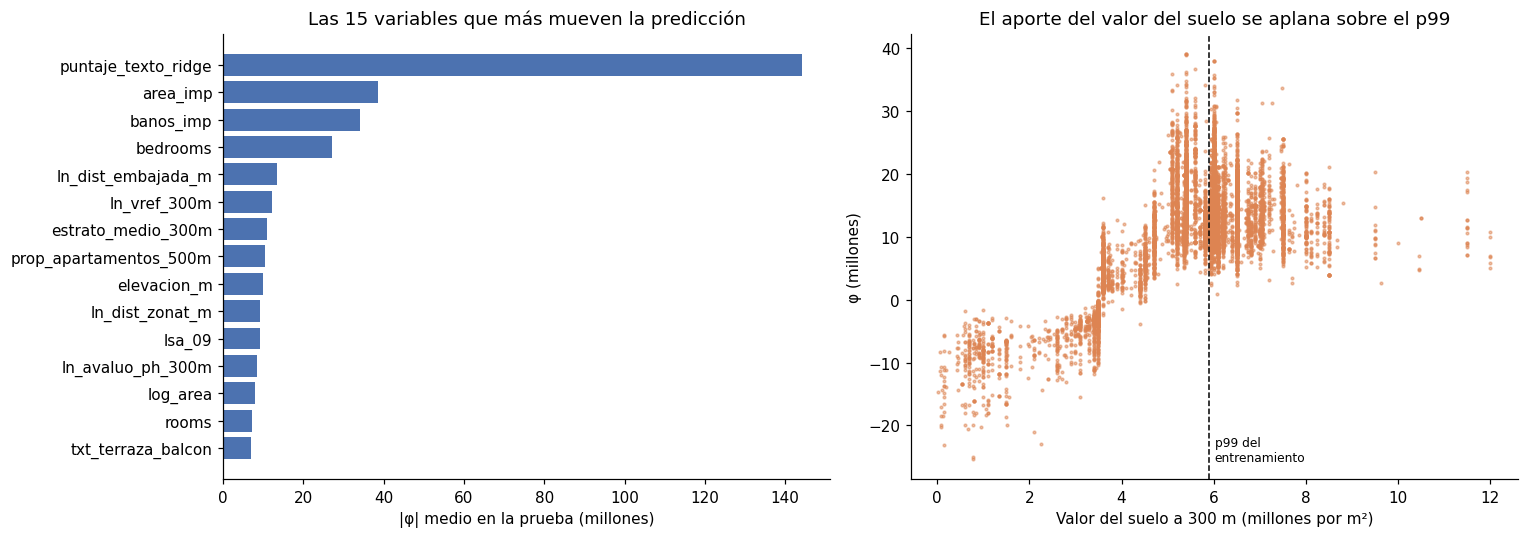

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t = top[::-1]
axes[0].barh(t.index, t.values, color="#4C72B0")
axes[0].set(xlabel="|φ| medio en la prueba (millones)", title="Las 15 variables que más mueven la predicción")
v = "ln_vref_300m"
axes[1].scatter(np.exp(valores_te[v]) / 1e6, shap_te[v], s=3, color="#DD8452", alpha=0.5, label="prueba (Chapinero)")
p99 = np.exp(np.nanpercentile(g[v].values[idx_tr], 99)) / 1e6
axes[1].axvline(p99, color="black", ls="--", lw=1)
axes[1].text(p99 * 1.02, axes[1].get_ylim()[0] * 0.9, "p99 del\nentrenamiento", fontsize=8)
axes[1].set(xlabel="Valor del suelo a 300 m (millones por m²)", ylabel="φ (millones)",
            title="El aporte del valor del suelo se aplana sobre el p99")
fig.tight_layout()
guardar_figura(fig, "shap")
plt.show()

Lectura. El texto aporta casi la mitad del movimiento de la predicción, y la variable individual más importante es el
puntaje de texto (ridge sobre TF-IDF). En el valor del suelo el aporte deja de crecer por encima del p99 del entrenamiento:
es la falta de extrapolación de los árboles, vista desde dentro del modelo.

## 6. ¿Se puede usar para comprar? Simulación de ofertas

Supuestos: la empresa ofrece $O_i = (1 - m)\,\hat y_i$ con un margen $m$; el dueño acepta si la oferta es al menos
$(1 - d)$ veces el valor $V_i$ (acepta vender hasta un $d$ por debajo); la ganancia de una compra es $V_i - O_i$. El valor
se aproxima con el precio publicado, así que la regla aplica a dueños que no publican precio, como en Zillow Offers:

$$\text{acepta}_i = \mathbb{1}\{(1 - m)\hat y_i \ge (1 - d) V_i\}, \qquad
\text{ganancia por oferta} = \frac{1}{n}\sum_i \text{acepta}_i\,(V_i - O_i)$$

Las ofertas que se aceptan son justamente las que el modelo sobrestimó: maldición del ganador.

In [9]:
filas = []
for nombre, o in ESQ.items():
    V, Pr = o["real"].to_numpy(), o["pf"].to_numpy()
    for d in (0.05, 0.10):
        for m in np.round(np.arange(0, 0.351, 0.05), 2):
            Of = (1 - m) * Pr
            acc = Of >= (1 - d) * V
            pierde = acc & (Of > V)
            filas.append({"validación": nombre, "d": d, "m": m, "% aceptadas": 100 * acc.mean(),
                          "% de las compras que pagan de más": 100 * pierde.sum() / max(acc.sum(), 1),
                          "ganancia por oferta": (V - Of)[acc].sum() / len(V), "ganancia por compra": (V - Of)[acc].mean()})
comp = pd.DataFrame(filas)
ref = pd.read_csv(cu.DATOS_PPT / "ppt_compras.csv")
print("Diferencia máxima con ppt_compras.csv:", coma(np.abs(comp["ganancia por oferta"].values - ref["ganancia_por_oferta"].values).max(), 6))
o = ESQ["Chapinero fuera"]
for col, et in (("pf", "con ×1,08"), ("pred", "sin ajuste")):
    V, Of = o["real"].to_numpy(), 0.9 * o[col].to_numpy()
    acc = Of >= 0.9 * V
    print(f"Chapinero fuera, m = d = 10 %, predicción {et}: de 100 ofertas se aceptan {coma(100 * acc.mean(), 0)}, "
          f"{coma(100 * (acc & (Of > V)).mean(), 0)} pagan de más; ganancia por oferta {coma((V - Of)[acc].sum() / len(V))} millones")
c_ = comp[comp["d"] == 0.10].drop(columns="d")
tabla_coma(c_).assign(m=c_["m"].map(lambda v: f"{int(round(100 * v))} %")).set_index(["validación", "m"])

Diferencia máxima con ppt_compras.csv: 0,000000
Chapinero fuera, m = d = 10 %, predicción con ×1,08: de 100 ofertas se aceptan 44, 26 pagan de más; ganancia por oferta -14,8 millones
Chapinero fuera, m = d = 10 %, predicción sin ajuste: de 100 ofertas se aceptan 43, 25 pagan de más; ganancia por oferta -13,2 millones


% aceptadas % de las compras que pagan de más  \
validación      m                                                    
kNNDM           0 %         73,3                              71,7   
                5 %         63,7                              64,7   
                10 %        52,5                              58,6   
                15 %        40,0                              54,4   
                20 %        28,6                              51,2   
                25 %        19,4                              48,6   
                30 %        12,1                              46,6   
                35 %         7,2                              44,0   
Chapinero fuera 0 %         66,8                              65,4   
                5 %         55,0                              63,9   
                10 %        43,6                              59,7   
                15 %        33,9                              52,9   
                20 %        23,8                              46,6   
                25 %        15,3                              51,1   
                30 %        10,4                              40,6   
                35 %         6,2                              36,8   

                     ganancia por oferta ganancia por compra  
validación      m                                             
kNNDM           0 %                -49,2               -67,2  
                5 %                -32,7               -51,3  
                10 %               -20,2               -38,5  
                15 %               -11,9               -29,7  
                20 %                -6,6               -23,1  
                25 %                -3,4               -17,4  
                30 %                -1,6               -13,6  
                35 %                -0,7                -9,8  
Chapinero fuera 0 %                -39,0               -58,4  
                5 %                -25,2               -45,8  
                10 %               -14,8               -33,9  
                15 %                -7,3               -21,5  
                20 %                -4,5               -19,1  
                25 %                -1,9               -12,7  
                30 %                -0,1                -1,1  
                35 %                 0,4                 6,9

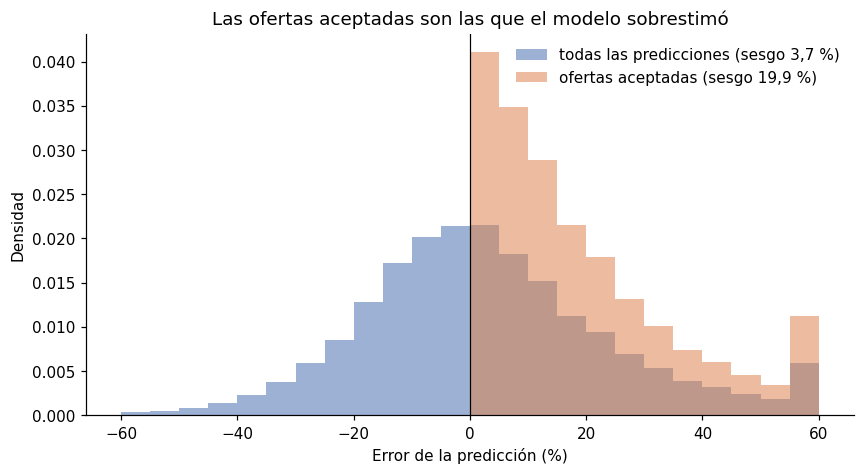

In [10]:
# Maldición del ganador en kNNDM (m = d = 10 %): error de todas las predicciones frente al de las ofertas aceptadas
o = ESQ["kNNDM"]
err = 100 * (o["pf"] / o["real"] - 1)
acc = 0.9 * o["pf"] >= 0.9 * o["real"]
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(-60, 65, 5)
ax.hist(err.clip(-59.9, 59.9), bins, density=True, alpha=0.55, color="#4C72B0", label=f"todas las predicciones (sesgo {coma(err.mean())} %)")
ax.hist(err[acc].clip(-59.9, 59.9), bins, density=True, alpha=0.55, color="#DD8452",
        label=f"ofertas aceptadas (sesgo {coma(err[acc].mean())} %)")
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Error de la predicción (%)", ylabel="Densidad", title="Las ofertas aceptadas son las que el modelo sobrestimó")
ax.legend(frameon=False)
guardar_figura(fig, "maldicion_ganador")
plt.show()

### 6.1 Precisión necesaria

¿Cuánto tendría que bajar el error para que las ofertas automáticas con margen de 10 % dejen ganancia? Se simula un modelo
hipotético con el error logarítmico de nuestro modelo multiplicado por $\lambda \in (0, 1]$, que conserva la forma de los
errores (incluido el sesgo hacia abajo en Chapinero):

$$\hat y_i(\lambda) = V_i \exp\!\big(\lambda \ln(\hat y_i / V_i)\big)$$

Para cada $\lambda$ se calcula el error absoluto mediano y la ganancia por oferta con $m = 10\,\%$, y se interpola el
error al que la ganancia cruza el cero.

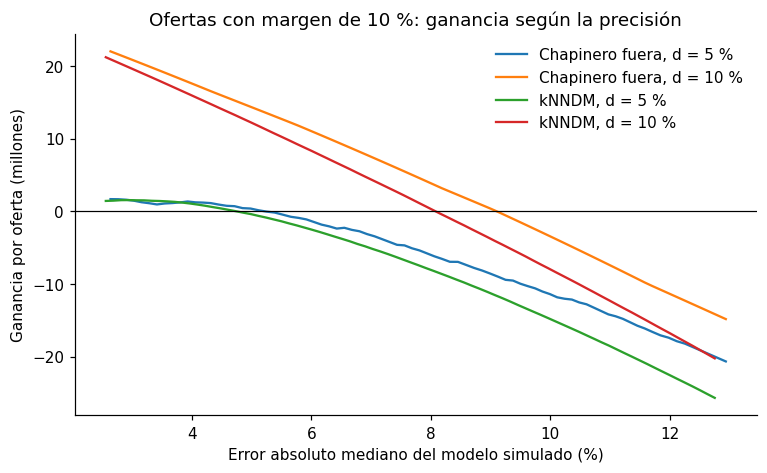

error mediano actual (%)  \
validación      d (el dueño acepta hasta)                            
Chapinero fuera 5 % menos                                     12,9   
                10 % menos                                    12,9   
kNNDM           5 % menos                                     12,8   
                10 % menos                                    12,8   

                                          error mediano necesario (%)  
validación      d (el dueño acepta hasta)                              
Chapinero fuera 5 % menos                                         5,2  
                10 % menos                                        9,1  
kNNDM           5 % menos                                         4,8  
                10 % menos                                        8,1

In [11]:
filas = []
for nombre, o in ESQ.items():
    V, le = o["real"].to_numpy(), np.log(o["pf"].to_numpy() / o["real"].to_numpy())
    for lam in np.round(np.arange(1.0, 0.19, -0.01), 2):
        P = V * np.exp(lam * le)
        em = 100 * np.median(np.abs(P / V - 1))
        for d in (0.05, 0.10):
            Of = 0.9 * P
            acc = Of >= (1 - d) * V
            filas.append({"validación": nombre, "lambda": lam, "error mediano (%)": em, "d": d,
                          "ganancia por oferta": (V - Of)[acc].sum() / len(V)})
prec = pd.DataFrame(filas)
umbral = []
for (nombre, d), t in prec.groupby(["validación", "d"]):
    t = t.sort_values("error mediano (%)")
    s = np.sign(t["ganancia por oferta"].values)
    k = np.where((s[:-1] > 0) & (s[1:] <= 0))[0]
    if len(k):
        k = k[-1]
        x0, x1 = t["error mediano (%)"].values[k:k + 2]
        y0, y1 = t["ganancia por oferta"].values[k:k + 2]
        cruce = x0 + (0 - y0) * (x1 - x0) / (y1 - y0)
    else:
        cruce = np.nan
    actual = 100 * np.median(np.abs(ESQ[nombre]["pf"] / ESQ[nombre]["real"] - 1))
    umbral.append({"validación": nombre, "d (el dueño acepta hasta)": f"{int(100 * d)} % menos",
                   "error mediano actual (%)": actual, "error mediano necesario (%)": cruce})
fig, ax = plt.subplots(figsize=(8, 4.5))
for (nombre, d), t in prec.groupby(["validación", "d"]):
    ax.plot(t["error mediano (%)"], t["ganancia por oferta"], label=f"{nombre}, d = {int(100 * d)} %")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Error absoluto mediano del modelo simulado (%)", ylabel="Ganancia por oferta (millones)",
       title="Ofertas con margen de 10 %: ganancia según la precisión")
ax.legend(frameon=False)
guardar_figura(fig, "precision_necesaria")
plt.show()
tabla_coma(pd.DataFrame(umbral).set_index(["validación", "d (el dueño acepta hasta)"]))

## 7. Conclusión para el negocio

| Pregunta | Respuesta con los errores fuera de muestra |
|---|---|
| ¿Sobrestima o subestima? | En Bogotá está calibrado; en Chapinero subestima en todos los quintiles (sesgo de −41 millones con el ×1,08) |
| ¿Dónde falla más? | En los avisos caros y en los que tienen variables fuera del rango del entrenamiento, aunque el error porcentual no cambia mucho entre grupos |
| ¿Se puede comprar con ofertas automáticas? | No. Con margen y descuento de 10 %, de 100 ofertas en Chapinero se aceptan 44 y 26 pagan de más; se pierden 14,8 millones por oferta |
| ¿Qué precisión haría falta? | Un error mediano cercano a 9 % si los dueños aceptan 10 % menos, o a 5 % si aceptan 5 % menos; hoy es 12,9 % en Chapinero |
| Recomendación | Usar el modelo como filtro y ancla de negociación: revisar avisos, ofertar el menor valor entre la predicción con margen y el precio pedido, con inspección humana. Para ofertar conviene la predicción sin el ×1,08, que pierde menos (−13,2 frente a −14,8 millones por oferta) |

In [12]:
print(f"Tiempo del cuaderno: {coma((time.time() - t0) / 60)} minutos")

Tiempo del cuaderno: 0,3 minutos
